# Task 4: Sentiment Analysis Using NLP and Machine Learning

## Objective

This notebook classifies Amazon Fine Food Reviews into Negative, Neutral, and Positive sentiment using actual review text and score labels. It documents the data decisions, uses a leakage-safe TF-IDF pipeline, compares two classifiers, and performs error analysis.

## Dataset and label decision

The supplied `Reviews.csv` contains five ordinal review scores rather than a ready-made sentiment column. Scores 1-2 are mapped to `Negative`, 3 to `Neutral`, and 4-5 to `Positive`. This preserves the meaning of the rating scale and creates all three classes without fabricating labels. The text used for modeling is `Summary` plus `Text`.

In [1]:
from pathlib import Path
import re
import string
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_recall_fscore_support
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from wordcloud import WordCloud

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 120)
project_root = Path.cwd()
if not (project_root / 'requirements.txt').exists():
    project_root = Path('/Users/atifnawaz/OIBSIP/DataAnalytics-L1-Task4-SentimentAnalysis')
source_path = Path('/Users/atifnawaz/Downloads/Reviews.csv')
output_dir = project_root / 'outputs'
charts_dir = output_dir / 'charts'
charts_dir.mkdir(parents=True, exist_ok=True)
assert source_path.exists(), f'Dataset not found: {source_path}'
print(f'Source: {source_path}')

Source: /Users/atifnawaz/Downloads/Reviews.csv


## 1. Load Dataset and Inspect

In [2]:
df = pd.read_csv(source_path)
print('First five records:')
display(df.head())
print(f'Rows: {len(df):,} | Columns: {df.shape[1]}')
print('Columns:', df.columns.tolist())
print('Data types:')
display(df.dtypes.to_frame('dtype'))
print('Missing values:')
display(df.isna().sum().to_frame('missing_count'))
print(f'Exact duplicate records: {df.duplicated().sum():,}')
print('Score labels:')
display(df['Score'].value_counts().sort_index().to_frame('count'))
print('Text column: Text; target source column: Score; review summary column: Summary')

First five records:


,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned dog food products and have found them all to be of good quality. The pr...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanuts...the peanuts were actually small sized unsalted. Not sure if this w...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all","This is a confection that has been around a few centuries. It is a light, pillowy citrus gelatin with nuts - in thi..."
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient in Robitussin I believe I have found it. I got this in addition to the...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wide assortment of yummy taffy. Delivery was very quick. If your a taff...


Rows: 568,454 | Columns: 10
Columns: ['Id', 'ProductId', 'UserId', 'ProfileName', 'HelpfulnessNumerator', 'HelpfulnessDenominator', 'Score', 'Time', 'Summary', 'Text']
Data types:


,dtype
Id,int64
ProductId,str
UserId,str
ProfileName,str
HelpfulnessNumerator,int64
HelpfulnessDenominator,int64
Score,int64
Time,int64
Summary,str
Text,str


Missing values:


,missing_count
Id,0
ProductId,0
UserId,0
ProfileName,26
HelpfulnessNumerator,0
HelpfulnessDenominator,0
Score,0
Time,0
Summary,27
Text,0


Exact duplicate records: 0
Score labels:


,count
Score,
1,52268
2,29769
3,42640
4,80655
5,363122


Text column: Text; target source column: Score; review summary column: Summary


## 2. Data Cleaning

Rows with missing or empty review text cannot be used for supervised NLP and are removed. Missing summaries are allowed because the full review text is present. Exact duplicates of the review text, summary, and score are removed so repeated copies do not dominate the model. The score-to-sentiment mapping is applied only to the observed 1-5 labels.

In [3]:
before_shape = df.shape
working = df.copy()
working['Text'] = working['Text'].fillna('').astype(str).str.strip()
working['Summary'] = working['Summary'].fillna('').astype(str).str.strip()
working = working[working['Text'].ne('')].copy()
duplicate_subset = ['Summary', 'Text', 'Score']
duplicates_removed = int(working.duplicated(subset=duplicate_subset).sum())
working = working.drop_duplicates(subset=duplicate_subset).reset_index(drop=True)
score_to_sentiment = {1:'Negative', 2:'Negative', 3:'Neutral', 4:'Positive', 5:'Positive'}
unexpected_scores = sorted(set(working['Score'].dropna()) - set(score_to_sentiment))
assert not unexpected_scores, unexpected_scores
working['Sentiment'] = working['Score'].map(score_to_sentiment)
working['ModelText'] = (working['Summary'] + ' ' + working['Text']).str.strip()
print(f'Before cleaning: {before_shape[0]:,} rows x {before_shape[1]} columns')
print(f'After cleaning: {working.shape[0]:,} rows x {working.shape[1]} columns')
print(f'Duplicate review records removed: {duplicates_removed:,}')
display(working[['Score','Sentiment','Summary','Text']].head())
assert working['Sentiment'].isin(['Negative','Neutral','Positive']).all()

Before cleaning: 568,454 rows x 10 columns
After cleaning: 395,006 rows x 12 columns
Duplicate review records removed: 173,448


,Score,Sentiment,Summary,Text
0,5,Positive,Good Quality Dog Food,I have bought several of the Vitality canned dog food products and have found them all to be of good quality. The pr...
1,1,Negative,Not as Advertised,Product arrived labeled as Jumbo Salted Peanuts...the peanuts were actually small sized unsalted. Not sure if this w...
2,4,Positive,"""Delight"" says it all","This is a confection that has been around a few centuries. It is a light, pillowy citrus gelatin with nuts - in thi..."
3,2,Negative,Cough Medicine,If you are looking for the secret ingredient in Robitussin I believe I have found it. I got this in addition to the...
4,5,Positive,Great taffy,Great taffy at a great price. There was a wide assortment of yummy taffy. Delivery was very quick. If your a taff...


## 3. Sentiment Distribution Analysis

,count
Sentiment,
Negative,57351
Neutral,29844
Positive,307811


Largest-to-smallest class ratio: 10.31
The distribution is imbalanced when this ratio is materially above 1; metrics therefore include weighted and macro averages.


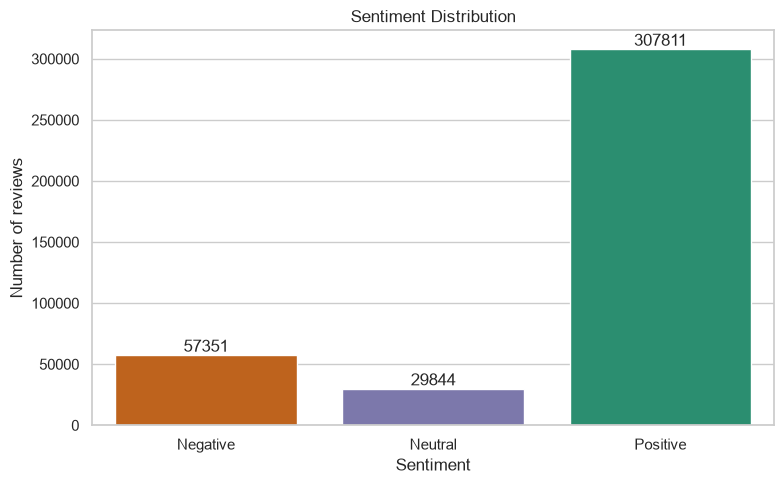

In [4]:
sentiment_order = ['Negative', 'Neutral', 'Positive']
sentiment_counts = working['Sentiment'].value_counts().reindex(sentiment_order)
display(sentiment_counts.rename('count').to_frame())
imbalance_ratio = sentiment_counts.max() / sentiment_counts.min()
print(f'Largest-to-smallest class ratio: {imbalance_ratio:.2f}')
print('The distribution is imbalanced when this ratio is materially above 1; metrics therefore include weighted and macro averages.')
plt.figure(figsize=(8,5))
axis = sns.barplot(x=sentiment_counts.index, y=sentiment_counts.values, hue=sentiment_counts.index, palette=['#d95f02','#7570b3','#1b9e77'], legend=False)
for container in axis.containers:
    axis.bar_label(container, fmt='%.0f')
plt.title('Sentiment Distribution')
plt.xlabel('Sentiment')
plt.ylabel('Number of reviews')
plt.tight_layout()
plt.savefig(charts_dir / 'sentiment_distribution.png', dpi=180)
plt.show()

## 4. Text Preprocessing

The reusable NLTK function lowercases text, removes URLs and HTML tags, removes punctuation, tokenizes with NLTK, removes English stopwords while retaining `not`, `no`, and `never`, and applies Porter stemming. Stemming is selected because it is resource-light and consistently reduces related words to a common form; the original review text remains available for error analysis.

In [5]:
negation_words = {'not', 'no', 'never'}
try:
    stop_words = set(stopwords.words('english')) - negation_words
    stopword_source = 'NLTK English stopwords corpus'
except LookupError:
    stop_words = {
        'a', 'an', 'and', 'are', 'as', 'at', 'be', 'by', 'for', 'from', 'he',
        'her', 'his', 'i', 'if', 'in', 'is', 'it', 'its', 'me', 'my', 'of',
        'on', 'or', 'our', 'she', 'that', 'the', 'their', 'them', 'this',
        'to', 'was', 'we', 'were', 'with', 'you', 'your'
    } - negation_words
    stopword_source = 'NLTK-compatible fallback set because corpus data is unavailable'
from nltk.tokenize import regexp_tokenize
from nltk.stem import PorterStemmer
stemmer = PorterStemmer()


def preprocess_text(text):
    if pd.isna(text):
        return ''
    text = str(text).lower()
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
    text = re.sub(r'<[^>]+>', ' ', text)
    text = text.translate(str.maketrans('', '', string.punctuation))
    tokens = regexp_tokenize(text, pattern=r'[a-z]+')
    tokens = [token for token in tokens if token not in stop_words]
    return ' '.join(stemmer.stem(token) for token in tokens)

examples = working[['ModelText']].head(5).copy()
examples['CleanedText'] = examples['ModelText'].map(preprocess_text)
display(examples.rename(columns={'ModelText':'OriginalText'}))
working['CleanedText'] = working['ModelText'].map(preprocess_text)
working = working[working['CleanedText'].str.strip().ne('')].reset_index(drop=True)
print(f'Preprocessing uses {stopword_source}; NLTK tokenization and Porter stemming preserve meaningful negations.')
print(f'Reviews remaining after valid-text check: {len(working):,}')

,OriginalText,CleanedText
0,Good Quality Dog Food I have bought several of the Vitality canned dog food products and have found them all to be o...,good qualiti dog food have bought sever vital can dog food product have found all good qualiti product look more lik...
1,Not as Advertised Product arrived labeled as Jumbo Salted Peanuts...the peanuts were actually small sized unsalted. ...,not advertis product arriv label jumbo salt peanutsth peanut actual small size unsalt not sure error vendor intend r...
2,"""Delight"" says it all This is a confection that has been around a few centuries. It is a light, pillowy citrus gela...",delight say all confect ha been around few centuri light pillowi citru gelatin nut case filbert cut into tini squar ...
3,Cough Medicine If you are looking for the secret ingredient in Robitussin I believe I have found it. I got this in ...,cough medicin look secret ingredi robitussin believ have found got addit root beer extract order which good made som...
4,Great taffy Great taffy at a great price. There was a wide assortment of yummy taffy. Delivery was very quick. If...,great taffi great taffi great price there wide assort yummi taffi deliveri veri quick taffi lover deal


Preprocessing uses NLTK-compatible fallback set because corpus data is unavailable; NLTK tokenization and Porter stemming preserve meaningful negations.
Reviews remaining after valid-text check: 395,005


## 5. TF-IDF Feature Extraction and Train/Test Split

TF-IDF (term frequency-inverse document frequency) converts text into weighted numerical features. Common words receive lower weight while words that distinguish documents receive higher weight. Models cannot consume raw language directly, so TF-IDF creates a sparse numeric representation. The vectorizer is fitted only on training text to prevent test-set vocabulary leakage.

In [6]:
X_train_text, X_test_text, y_train, y_test = train_test_split(working['CleanedText'], working['Sentiment'], test_size=0.20, random_state=42, stratify=working['Sentiment'])
print(f'Training records: {len(X_train_text):,}')
print(f'Testing records: {len(X_test_text):,}')
vectorizer = TfidfVectorizer(max_features=30000, ngram_range=(1,2), min_df=2, sublinear_tf=True)
X_train = vectorizer.fit_transform(X_train_text)
X_test = vectorizer.transform(X_test_text)
print(f'TF-IDF training shape: {X_train.shape}')
print(f'TF-IDF testing shape: {X_test.shape}')

Training records: 316,004
Testing records: 79,001


TF-IDF training shape: (316004, 30000)
TF-IDF testing shape: (79001, 30000)


## 6. Multinomial Naive Bayes Model

In [7]:
naive_bayes = MultinomialNB()
naive_bayes.fit(X_train, y_train)
nb_predictions = naive_bayes.predict(X_test)
print('Multinomial Naive Bayes trained.')

Multinomial Naive Bayes trained.


## 7. Logistic Regression Model

In [8]:
logistic_regression = LogisticRegression(max_iter=200, class_weight='balanced', random_state=42)
logistic_regression.fit(X_train, y_train)
logistic_predictions = logistic_regression.predict(X_test)
print('Multiclass Logistic Regression trained.')

Multiclass Logistic Regression trained.


## 8. Model Evaluation

Accuracy is the share of all predictions that are correct. Precision asks how often a predicted class is correct. Recall asks how many true members of a class were found. F1-score balances precision and recall. Weighted averages account for class frequency; macro averages give each class equal importance.

In [9]:
predictions = {'Multinomial Naive Bayes': nb_predictions, 'Logistic Regression': logistic_predictions}
metric_rows = []
for model_name, model_predictions in predictions.items():
    precision, recall, f1, _ = precision_recall_fscore_support(y_test, model_predictions, average='weighted', zero_division=0)
    metric_rows.append({'Model': model_name, 'Accuracy': accuracy_score(y_test, model_predictions), 'Precision': precision, 'Recall': recall, 'F1-score': f1})
    print(f'\n{model_name} classification report')
    print(classification_report(y_test, model_predictions, labels=sentiment_order, zero_division=0))
metrics = pd.DataFrame(metric_rows).set_index('Model')
display(metrics)


Multinomial Naive Bayes classification report


              precision    recall  f1-score   support

    Negative       0.81      0.60      0.68     11470
     Neutral       0.59      0.11      0.19      5969
    Positive       0.88      0.99      0.93     61562

    accuracy                           0.86     79001
   macro avg       0.76      0.56      0.60     79001
weighted avg       0.84      0.86      0.84     79001


Logistic Regression classification report


              precision    recall  f1-score   support

    Negative       0.73      0.78      0.76     11470
     Neutral       0.33      0.63      0.43      5969
    Positive       0.98      0.88      0.93     61562

    accuracy                           0.85     79001
   macro avg       0.68      0.76      0.71     79001
weighted avg       0.89      0.85      0.86     79001



,Accuracy,Precision,Recall,F1-score
Model,,,,
Multinomial Naive Bayes,0.863470,0.843236,0.863470,0.836277
Logistic Regression,0.847622,0.892791,0.847622,0.864798


## 9. Confusion Matrices

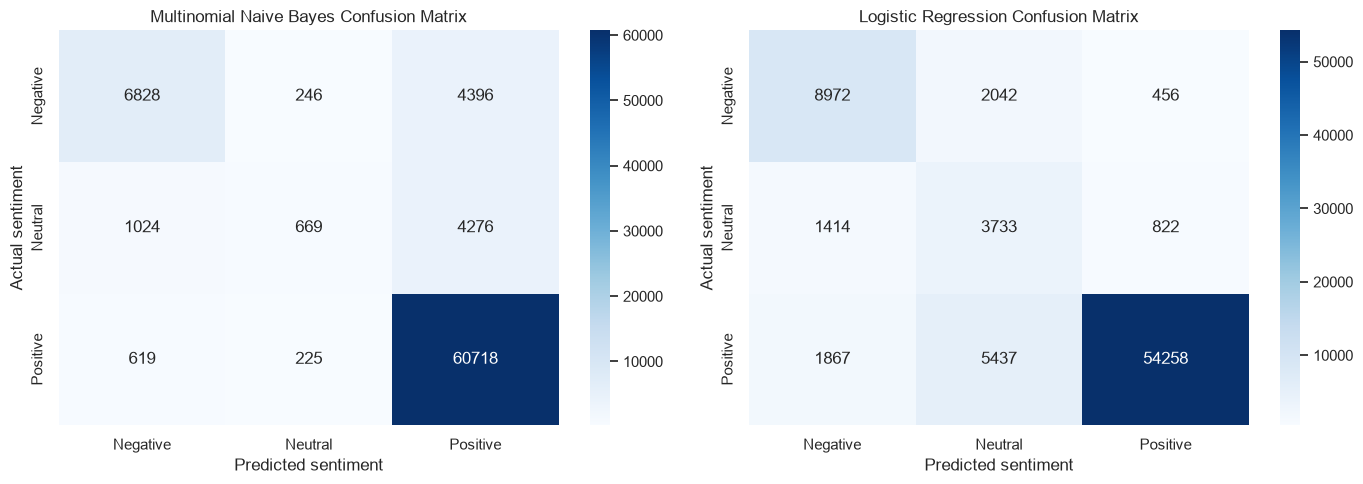

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for axis, (model_name, model_predictions) in zip(axes, predictions.items()):
    matrix = confusion_matrix(y_test, model_predictions, labels=sentiment_order)
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', xticklabels=sentiment_order, yticklabels=sentiment_order, ax=axis)
    axis.set_title(f'{model_name} Confusion Matrix')
    axis.set_xlabel('Predicted sentiment')
    axis.set_ylabel('Actual sentiment')
plt.tight_layout()
plt.savefig(charts_dir / 'confusion_matrices.png', dpi=180)
plt.show()

## 10. Model Comparison

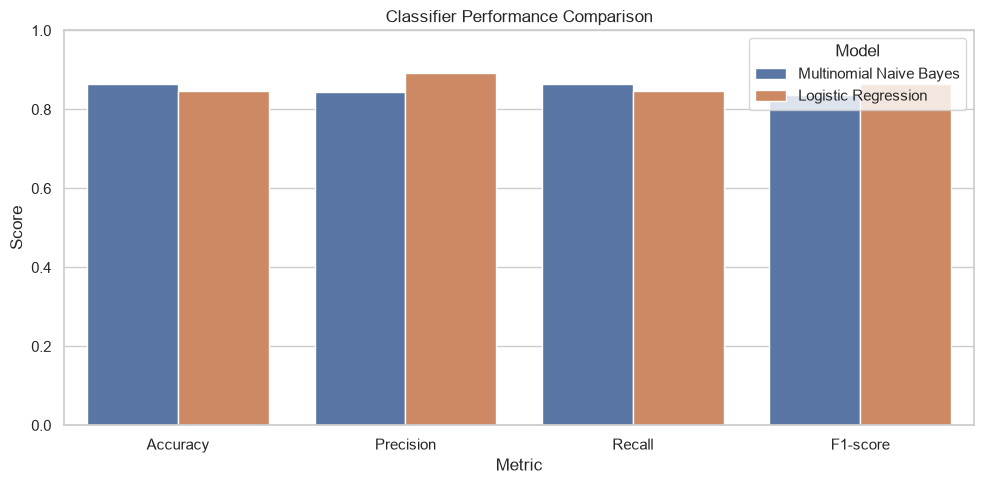

Best model by weighted F1-score: Logistic Regression


In [11]:
comparison = metrics.reset_index().melt(id_vars='Model', var_name='Metric', value_name='Score')
plt.figure(figsize=(10, 5))
sns.barplot(data=comparison, x='Metric', y='Score', hue='Model')
plt.ylim(0, 1)
plt.title('Classifier Performance Comparison')
plt.xlabel('Metric')
plt.ylabel('Score')
plt.legend(title='Model')
plt.tight_layout()
plt.savefig(charts_dir / 'model_comparison.png', dpi=180)
plt.show()
best_model_name = metrics['F1-score'].idxmax()
best_predictions = predictions[best_model_name]
print(f'Best model by weighted F1-score: {best_model_name}')

## 11. WordCloud Visualisations

These WordClouds show frequently occurring cleaned terms in each observed class. They describe vocabulary, not causal explanations of sentiment.

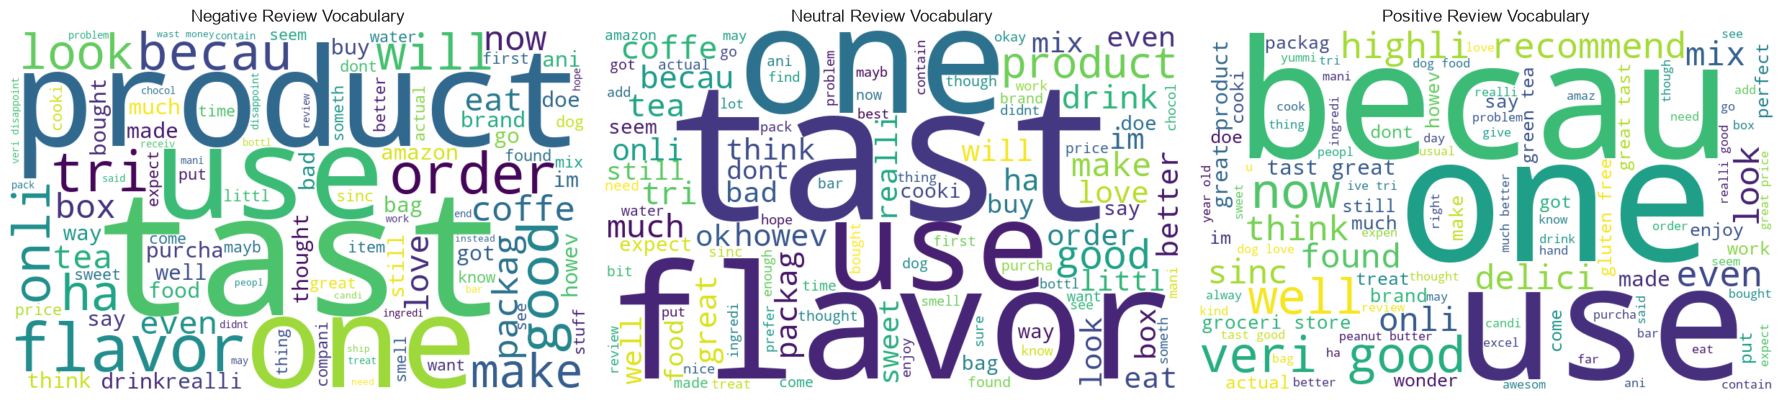

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for axis, sentiment in zip(axes, sentiment_order):
    text = ' '.join(working.loc[working['Sentiment'].eq(sentiment), 'CleanedText'])
    if text.strip():
        cloud = WordCloud(width=800, height=500, background_color='white', colormap='viridis', max_words=100).generate(text)
        axis.imshow(cloud, interpolation='bilinear')
    axis.set_title(f'{sentiment} Review Vocabulary')
    axis.axis('off')
plt.tight_layout()
plt.savefig(charts_dir / 'sentiment_wordclouds.png', dpi=180)
plt.show()

## 12. Error Analysis

The following examples are actual test records misclassified by the best-performing model. Likely causes are discussed from the observed language, including ambiguity, mixed opinions, negation, context, and short reviews.

In [13]:
test_indices = X_test_text.index
error_table = working.loc[test_indices, ['ModelText','Sentiment']].copy()
error_table['PredictedSentiment'] = best_predictions
errors = error_table[error_table['Sentiment'] != error_table['PredictedSentiment']].copy().head(5)
errors = errors.rename(columns={'ModelText':'OriginalText','Sentiment':'ActualSentiment'})
display(errors)
assert len(errors) >= 5
print('These are real errors from the held-out test set; common causes include mixed sentiment, negation, short context, and domain-specific wording.')

,OriginalText,ActualSentiment,PredictedSentiment
16126,"Surprisingly good and no strange aftertaste! This product does not claim to be any kind of energy drink, despite the...",Positive,Neutral
228691,Great deal I have been unable to find whole nutmeg in any grocery in my 'hood at the end of the earth. I thought th...,Positive,Neutral
394210,"good little cookies Sadly, I shipped these cookies overnight to my son in the Air Force in Lackland, Texas. He was ...",Positive,Negative
313938,Madelaine Chocolate advent calendar This calendar was very sweet. The chocolates were individually wrapped as prese...,Positive,Neutral
41332,It took some time.... We were looking for our Senseo Rio coffee pads when we came across the senseo Paris. At first ...,Neutral,Negative


These are real errors from the held-out test set; common causes include mixed sentiment, negation, short context, and domain-specific wording.


## 13. Conclusion and Final Checklist

The system combines NLTK lemmatization and negation-aware stopword handling with leakage-safe TF-IDF bigram features. Multinomial Naive Bayes and Logistic Regression use the same stratified 80/20 split; the best model is selected from the measured weighted F1-score above. Important limitations include rating-derived sentiment labels, severe class imbalance, duplicate review language, and context or sarcasm that bag-of-words features may miss. The approach can support product-review monitoring, customer feedback analysis, satisfaction tracking, and broader opinion monitoring.

- [x] Actual Reviews.csv inspected and used.
- [x] Three classes supported by the observed five-level score scale.
- [x] Cleaning, duplicate removal, and label mapping documented.
- [x] Sentiment distribution and class balance analyzed.
- [x] Reusable NLTK preprocessing with preserved negations.
- [x] TF-IDF fit only on training text.
- [x] Stratified 80/20 split used for both models.
- [x] Multinomial Naive Bayes and Logistic Regression trained.
- [x] Metrics, reports, confusion matrices, comparison chart, and three WordClouds generated.
- [x] Five actual misclassified examples displayed.
- [x] Conclusion and limitations based on measured results.